# Inventory Shrinkage & Stock Efficiency Analysis
**Finding investigation priorities through record-level validation, exposure-adjusted rates, and inventory comparisons**

## 1. Project Overview
**Business question:** Which stores and products contribute most to recorded shrinkage, and where do stock-efficiency signals warrant operational investigation?

The main dataset is **`stock_months_validated.csv`**. Four supplied summary files provide rankings, coded-month totals, and median-based inefficiency flags. This notebook reads all five files, reproduces their calculations where documented by the data, and distinguishes unit volume, weighted shrink rate, and cost.

**Scope and interpretation:** Records represent store-product-coded-month observations. Currency, calendar dates, product/store names, shrink reasons, independent stock counts, and data provenance are not supplied. Cost values are numeric amounts without a verified denomination. A record-level reconciliation does not prove that the source is an audited inventory ledger.

**Run instructions:** In Colab, open the notebook and select **Runtime → Run all**. The loading code opens an upload dialog if inputs are missing; select the five supplied CSVs together. In local Jupyter, place the notebook beside those files and select **Restart Kernel and Run All**. All paths are relative, and existing inputs are never overwritten by the analysis.


## 2. Libraries and Data Loading
If necessary, run `%pip install pandas numpy matplotlib seaborn jinja2` in a separate cell, restart the runtime, and run all cells. The installed versions are recorded below. No additional datasets, internet downloads, or credentials are required.


In [1]:
from pathlib import Path
from importlib.metadata import version
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns
from IPython.display import Markdown, display

DATA_DIR = Path('.')  # Folder containing the five supplied CSV files.
RTOL, ATOL = 1e-9, 1e-7
BLUE, ORANGE, GRAY = '#315b7d', '#bc613d', '#84929b'
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({
    'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False,
    'axes.titleweight':'bold', 'axes.titlesize':12, 'axes.labelsize':10,
    'grid.alpha':0.25,
})
pd.set_option('display.max_rows', 25)
pd.set_option('display.max_columns', 12)
versions = {'Python':platform.python_version()}
versions.update({name:version(name) for name in
                 ['pandas','numpy','matplotlib','seaborn','jinja2']})
display(pd.Series(versions, name='Version').to_frame())


,Version
Python,3.13.18
pandas,2.2.3
numpy,2.1.3
matplotlib,3.10.0
seaborn,0.13.2
jinja2,3.1.6


In [3]:
required_files = {
    'main':'stock_months_validated.csv',
    'stores':'store_shrinkage_rankings.csv',
    'products':'product_rankings_complete.csv',
    'months':'monthly_shrinkage_summary.csv',
    'overlap':'inefficiency_overlap_summary.csv',
}
missing_files = [name for name in required_files.values() if not (DATA_DIR/name).is_file()]
if missing_files:
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError(
            f'Missing {missing_files}. Place the CSVs beside the notebook, '
            'or set DATA_DIR to their relative folder.'
        ) from error
    print('Select the five supplied CSVs together. Missing inputs:')
    for filename in missing_files:
        print(' -', filename)
    uploaded_files = files.upload()
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    for filename in missing_files:
        destination = DATA_DIR/filename
        if not destination.is_file() and filename in uploaded_files:
            destination.write_bytes(uploaded_files[filename])
    del uploaded_files
missing_files = [name for name in required_files.values() if not (DATA_DIR/name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Still missing {missing_files}. Upload the exact filenames and rerun this cell.')

source_frames = {key:pd.read_csv(DATA_DIR/name) for key,name in required_files.items()}
raw_inventory = source_frames['main']
store_rankings = source_frames['stores']
product_rankings = source_frames['products']
month_summary = source_frames['months']
overlap_summary = source_frames['overlap']
display(pd.DataFrame([
    {'File':required_files[key], 'Rows':len(frame), 'Columns':frame.shape[1]}
    for key,frame in source_frames.items()
]))
print('Main dataset columns:', raw_inventory.columns.tolist())
display(raw_inventory[['store_id','product_id','month_id','available_units',
                       'units_sold','shrink_units','shrink_cost']].head(3))

,File,Rows,Columns
0,stock_months_validated.csv,936,22
1,store_shrinkage_rankings.csv,6,14
2,product_rankings_complete.csv,13,9
3,monthly_shrinkage_summary.csv,12,10
4,inefficiency_overlap_summary.csv,31,15


Main dataset columns: ['store_id', 'product_id', 'month_id', 'opening_units', 'received_units', 'available_units', 'sell_through_base', 'sell_through', 'units_sold', 'unsold_units', 'shrink_base', 'store_shrink_rate', 'shrink_rate', 'shrink_units', 'closing_units', 'unit_cost', 'unit_price', 'cost_of_sales', 'sales_amount', 'shrink_cost', 'opening_value', 'closing_value']


,store_id,product_id,month_id,available_units,units_sold,shrink_units,shrink_cost
0,2,6,2,220,63,5,24.5
1,1,8,11,140,63,0,0.0
2,4,4,3,413,147,10,24.0


## 3. Data Quality and Metric Definitions
Inspect the actual columns, types, missingness, and keys before analysis. Every main-file field is numeric. Invalid values are reported and stop calculations rather than being imputed as zero. The analytical copy is separate from the original data.

| Measure | Definition used here |
| --- | --- |
| Available units | Opening units + received units within a record |
| Unsold units | Available units − units sold, before shrink |
| Closing units | Available units − units sold − shrink units |
| Weighted shrink rate | Sum of shrink units / sum of available units |
| Mean recorded shrink rate | Arithmetic mean of the supplied `shrink_rate` field |
| Count-based sell-through | Sum of units sold / sum of available units |
| Mean recorded sell-through | Arithmetic mean of the supplied `sell_through` field |
| Shrink cost | Shrink units × unit cost; not a verified cash loss or net-profit impact |

Summed available units represent **record-level inventory exposure**, not a count of distinct physical items. Closing balances are summarized as means across records, not added and described as a year-end stock position.


In [4]:
required_columns = {
    'store_id','product_id','month_id','opening_units','received_units','available_units',
    'sell_through_base','sell_through','units_sold','unsold_units','shrink_base',
    'store_shrink_rate','shrink_rate','shrink_units','closing_units','unit_cost',
    'unit_price','cost_of_sales','sales_amount','shrink_cost','opening_value','closing_value',
}
missing_columns = required_columns - set(raw_inventory.columns)
if missing_columns:
    raise ValueError(f'Main-file columns unavailable: {sorted(missing_columns)}')
quality = pd.DataFrame({
    'dtype':raw_inventory.dtypes.astype(str),
    'missing':raw_inventory.isna().sum(),
    'unique_nonmissing':raw_inventory.nunique(),
})
display(quality)
print('Exact duplicate records:', raw_inventory.duplicated().sum())
print('Duplicate store-product-month keys:',
      raw_inventory.duplicated(['store_id','product_id','month_id']).sum())

inventory = raw_inventory.copy()
invalid_values = {}
for column in sorted(required_columns):
    converted = pd.to_numeric(inventory[column], errors='coerce')
    invalid = inventory[column].notna() & (converted.isna() | ~np.isfinite(converted))
    invalid_values[column] = int(invalid.sum())
    inventory[column] = converted.where(np.isfinite(converted))
print('Invalid numeric conversions:', sum(invalid_values.values()))
if inventory[list(required_columns)].isna().any().any():
    raise ValueError('Required fields contain missing/invalid numbers; review the quality report before continuing.')
if inventory.duplicated(['store_id','product_id','month_id']).any():
    raise ValueError('Duplicate analytical keys require review; no automatic aggregation is applied.')

integer_columns = ['store_id','product_id','month_id','opening_units','received_units',
                   'available_units','units_sold','unsold_units','shrink_units','closing_units']
if any(not np.equal(inventory[c], np.floor(inventory[c])).all() for c in integer_columns):
    raise ValueError('IDs and unit counts must be whole numbers.')
if inventory[list(required_columns)].lt(0).any().any():
    raise ValueError('Unexpected negative values require review.')
rate_columns = ['sell_through_base','sell_through','shrink_base','store_shrink_rate','shrink_rate']
if inventory[rate_columns].gt(1).any().any():
    raise ValueError('Rate fields must be fractions between 0 and 1.')
if inventory.unit_cost.le(0).any() or inventory.available_units.le(0).any():
    raise ValueError('Positive unit costs and available units are needed for the planned comparisons.')
for column in integer_columns:
    inventory[column] = inventory[column].astype(int)
print('Unique stores/products/month codes:',
      inventory[['store_id','product_id','month_id']].nunique().to_dict())
print('Expected balanced combinations:',
      inventory.store_id.nunique()*inventory.product_id.nunique()*inventory.month_id.nunique())


,dtype,missing,unique_nonmissing
store_id,int64,0,6
product_id,int64,0,13
month_id,int64,0,12
opening_units,int64,0,320
received_units,int64,0,266
available_units,int64,0,433
sell_through_base,float64,0,221
sell_through,float64,0,318
units_sold,int64,0,253
unsold_units,int64,0,316


Exact duplicate records: 0
Duplicate store-product-month keys: 0
Invalid numeric conversions: 0
Unique stores/products/month codes: {'store_id': 6, 'product_id': 13, 'month_id': 12}
Expected balanced combinations: 936


## 4. Inventory Reconciliation
Check stock and value equations separately from cross-period continuity. The latter is conditional on treating increasing month codes as an ordered sequence; no calendar mapping is supplied. Balance differences may reflect undocumented resets or adjustments and are **not additional shrink losses**.


In [5]:
expected_values = {
    'available_units':inventory.opening_units + inventory.received_units,
    'unsold_units':inventory.available_units - inventory.units_sold,
    'closing_units':inventory.available_units - inventory.units_sold - inventory.shrink_units,
    'cost_of_sales':inventory.units_sold * inventory.unit_cost,
    'sales_amount':inventory.units_sold * inventory.unit_price,
    'shrink_cost':inventory.shrink_units * inventory.unit_cost,
    'opening_value':inventory.opening_units * inventory.unit_cost,
    'closing_value':inventory.closing_units * inventory.unit_cost,
}
reconciliation = pd.DataFrame([
    {'Field':field,
     'Mismatched records':int((~np.isclose(inventory[field], expected, rtol=RTOL, atol=ATOL)).sum()),
     'Maximum absolute difference':float(np.abs(inventory[field]-expected).max())}
    for field,expected in expected_values.items()
]).set_index('Field')
display(reconciliation.style.format({'Maximum absolute difference':'{:.2e}'}))
if reconciliation['Mismatched records'].sum():
    raise ValueError('Record-level stock/value identities failed; resolve before ranking records.')

ordered = inventory.sort_values(['store_id','product_id','month_id']).copy()
ordered['previous_month_id'] = ordered.groupby(['store_id','product_id']).month_id.shift()
ordered['previous_closing_units'] = ordered.groupby(['store_id','product_id']).closing_units.shift()
adjacent = ordered.month_id.sub(ordered.previous_month_id).eq(1)
continuity = ordered.loc[adjacent, ['store_id','product_id','month_id',
                                  'opening_units','previous_closing_units']].copy()
continuity['opening_minus_previous_close'] = continuity.opening_units - continuity.previous_closing_units
continuity_mismatches = int(continuity.opening_minus_previous_close.ne(0).sum())
print(f'Adjacent coded-period balance differences: {continuity_mismatches:,} of {len(continuity):,} pairs.')
display(continuity.loc[continuity.opening_minus_previous_close.ne(0)].head(5))
rounded_shrink_matches = np.equal(inventory.shrink_units,
                                  np.rint(inventory.unsold_units*inventory.shrink_rate))
print(f'Shrink units match rounded unsold units x recorded shrink rate in '
      f'{rounded_shrink_matches.sum():,} of {len(inventory):,} records.')


,Mismatched records,Maximum absolute difference
Field,,
available_units,0,0.00e+00
unsold_units,0,0.00e+00
closing_units,0,0.00e+00
cost_of_sales,0,2.27e-13
sales_amount,0,4.55e-13
shrink_cost,0,7.11e-15
opening_value,0,2.27e-13
closing_value,0,2.27e-13


Adjacent coded-period balance differences: 856 of 858 pairs.


,store_id,product_id,month_id,opening_units,previous_closing_units,opening_minus_previous_close
174,1,1,2,300,204.0,96.0
361,1,1,3,26,221.0,-195.0
814,1,1,4,35,159.0,-124.0
345,1,1,5,89,150.0,-61.0
707,1,1,6,336,68.0,268.0


Shrink units match rounded unsold units x recorded shrink rate in 936 of 936 records.


**Interpretation:** All record-level equations reconcile for the supplied data, but 856 of 858 adjacent coded-period balances differ. This supports record-level comparisons rather than a verified continuous stock ledger. The exact rounded relationship between shrink units and recorded rates is consistent with a calculation rule; it does not independently establish how real losses were observed. Source documentation and physical counts are still needed.


## 5. Portfolio Overview
The overview summarizes the main file directly. Recorded sales and shrink cost use different accounting meanings; shrink cost is not deducted and presented as an estimate of net profit. Mean recorded rate fields are shown separately from count-based ratios.


In [6]:
def summarize_inventory(frame, group_column):
    result = frame.groupby(group_column).agg(
        records=('available_units','size'), total_received_units=('received_units','sum'),
        total_units_sold=('units_sold','sum'), total_shrink_units=('shrink_units','sum'),
        total_shrink_cost=('shrink_cost','sum'), total_available_units=('available_units','sum'),
        total_sales_amount=('sales_amount','sum'), mean_closing_units=('closing_units','mean'),
        mean_sell_through=('sell_through','mean'), mean_recorded_shrink_rate=('shrink_rate','mean'),
        mean_recorded_store_shrink_rate=('store_shrink_rate','mean'),
    )
    result['weighted_shrink_rate'] = result.total_shrink_units / result.total_available_units
    result['count_based_sell_through'] = result.total_units_sold / result.total_available_units
    result['shrink_cost_share'] = result.total_shrink_cost / frame.shrink_cost.sum()
    for rank,metric in [('rank_total_shrink_units','total_shrink_units'),
                        ('rank_weighted_shrink_rate','weighted_shrink_rate'),
                        ('rank_total_shrink_cost','total_shrink_cost')]:
        result[rank] = result[metric].rank(ascending=False, method='min').astype(int)
    return result

computed_summaries = {
    'stores':summarize_inventory(inventory,'store_id'),
    'products':summarize_inventory(inventory,'product_id'),
    'months':summarize_inventory(inventory,'month_id'),
}
weighted_shrink_rate = inventory.shrink_units.sum()/inventory.available_units.sum()
count_sell_through = inventory.units_sold.sum()/inventory.available_units.sum()
portfolio = pd.DataFrame([
    ('Records',f'{len(inventory):,}'),
    ('Units sold',f'{inventory.units_sold.sum():,}'),
    ('Available-unit exposure across records',f'{inventory.available_units.sum():,}'),
    ('Recorded shrink units',f'{inventory.shrink_units.sum():,}'),
    ('Recorded shrink cost (currency unspecified)',f'{inventory.shrink_cost.sum():,.2f}'),
    ('Recorded sales amount (currency unspecified)',f'{inventory.sales_amount.sum():,.2f}'),
    ('Weighted count-based shrink rate',f'{weighted_shrink_rate:.2%}'),
    ('Mean recorded shrink rate',f'{inventory.shrink_rate.mean():.2%}'),
    ('Count-based sell-through',f'{count_sell_through:.2%}'),
    ('Mean recorded sell-through',f'{inventory.sell_through.mean():.2%}'),
    ('Mean closing units per record',f'{inventory.closing_units.mean():,.2f}'),
], columns=['Metric','Value']).set_index('Metric')
display(portfolio)
print('Records with zero recorded shrink units:',inventory.shrink_units.eq(0).sum())


,Value
Metric,
Records,936
Units sold,"99,840"
Available-unit exposure across records,"236,993"
Recorded shrink units,"3,248"
Recorded shrink cost (currency unspecified),"26,560.10"
Recorded sales amount (currency unspecified),"1,428,437.80"
Weighted count-based shrink rate,1.37%
Mean recorded shrink rate,2.36%
Count-based sell-through,42.13%


Records with zero recorded shrink units: 300


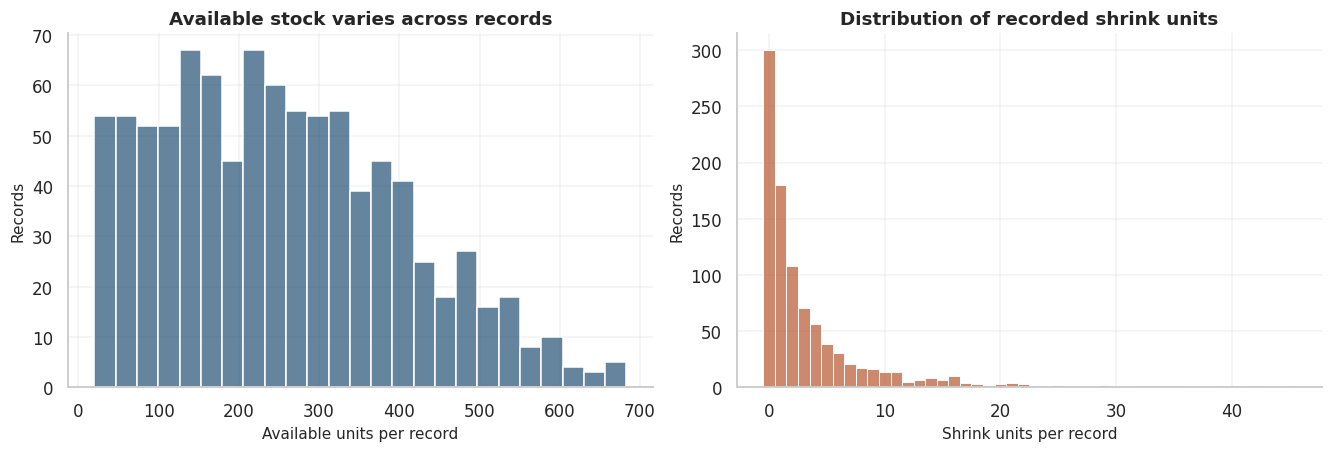

In [7]:
fig, axes = plt.subplots(1,2,figsize=(12,4),layout='constrained')
sns.histplot(data=inventory,x='available_units',bins=25,color=BLUE,ax=axes[0])
axes[0].set(title='Available stock varies across records',xlabel='Available units per record',ylabel='Records')
sns.histplot(data=inventory,x='shrink_units',discrete=True,color=ORANGE,ax=axes[1])
axes[1].set(title='Distribution of recorded shrink units',xlabel='Shrink units per record',ylabel='Records')
plt.show()


## 6. Store Performance
Compare all six stores by unit volume, weighted rate, and cost. A high unit total can reflect greater exposure; a high cost total can reflect more expensive product mix. These are descriptive priorities, not exposure-adjusted causal store effects.


,total_shrink_units,total_available_units,weighted_shrink_rate,total_shrink_cost,rank_total_shrink_units,rank_weighted_shrink_rate
store_id,,,,,,
5,772,"39,260",1.97%,"6,998.60",2,1
6,804,"41,960",1.92%,"5,653.40",1,2
4,573,"40,116",1.43%,"4,453.40",3,3
3,501,"39,321",1.27%,"3,984.00",4,4
2,368,"38,995",0.94%,"3,219.30",5,5
1,230,"37,341",0.62%,"2,251.40",6,6


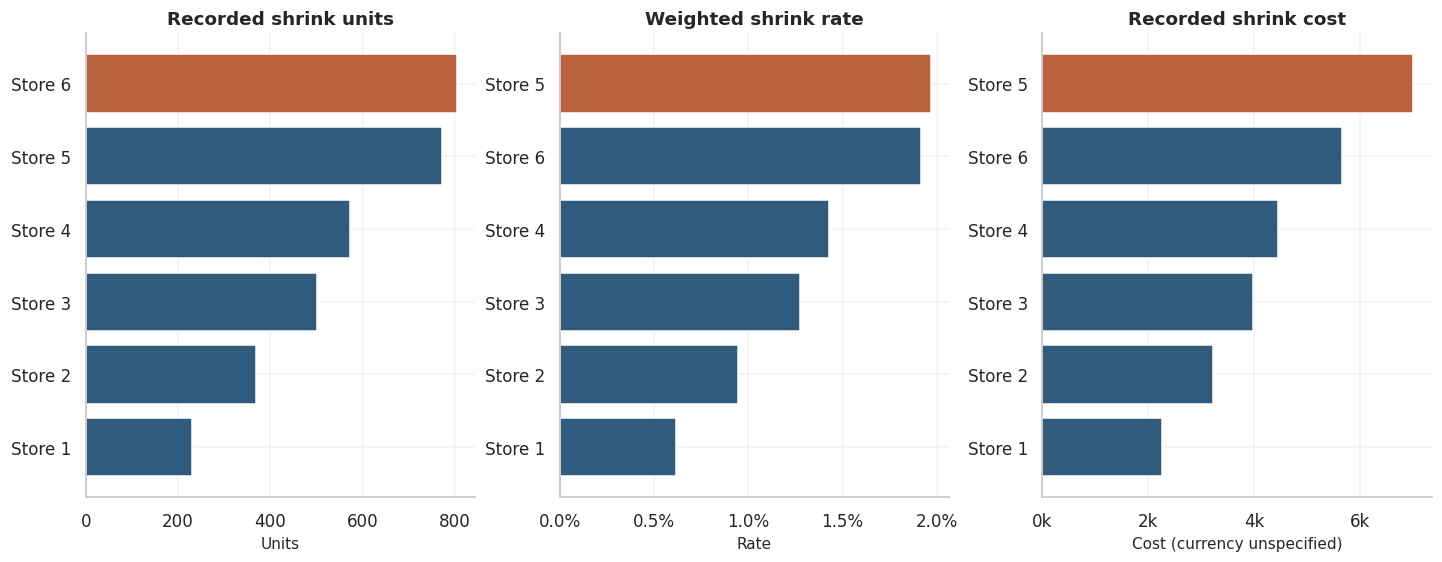

In [8]:
store_analysis = computed_summaries['stores'].sort_values('total_shrink_cost',ascending=False)
store_columns = ['total_shrink_units','total_available_units','weighted_shrink_rate',
                 'total_shrink_cost','rank_total_shrink_units','rank_weighted_shrink_rate']
display(store_analysis[store_columns].style.format({
    'total_shrink_units':'{:,}','total_available_units':'{:,}',
    'weighted_shrink_rate':'{:.2%}','total_shrink_cost':'{:,.2f}',
}))
fig, axes = plt.subplots(1,3,figsize=(13,5),layout='constrained')
for ax,metric,title in zip(axes,
    ['total_shrink_units','weighted_shrink_rate','total_shrink_cost'],
    ['Recorded shrink units','Weighted shrink rate','Recorded shrink cost']):
    ordered_stores = store_analysis.sort_values(metric,ascending=False)
    colors = [ORANGE if entity==ordered_stores.index[0] else BLUE for entity in ordered_stores.index]
    ax.barh(['Store '+str(x) for x in ordered_stores.index],ordered_stores[metric],color=colors)
    ax.invert_yaxis()
    ax.set(title=title,xlabel='Rate' if 'rate' in metric else ('Cost (currency unspecified)' if 'cost' in metric else 'Units'))
    if 'rate' in metric:
        ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=1))
    elif 'cost' in metric:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_:f'{x/1000:g}k'))
plt.show()


## 7. Product Priorities
Display all 13 products, then compare cost and rate orderings. Product names are unavailable, so identifiers remain codes. Avoid treating the highest-cost product as necessarily having the highest shrink rate.


,total_shrink_units,weighted_shrink_rate,total_shrink_cost,shrink_cost_share,rank_total_shrink_units
product_id,,,,,
1,387,2.26%,"10,836.00",40.8%,2
3,599,3.06%,"5,391.00",20.3%,1
13,239,1.48%,"3,346.00",12.6%,8
2,315,1.57%,"2,047.50",7.7%,3
9,291,1.47%,"1,396.80",5.3%,4
10,263,1.45%,815.30,3.1%,7
6,164,0.97%,803.60,3.0%,9
4,269,1.42%,645.60,2.4%,5
5,265,1.42%,477.00,1.8%,6


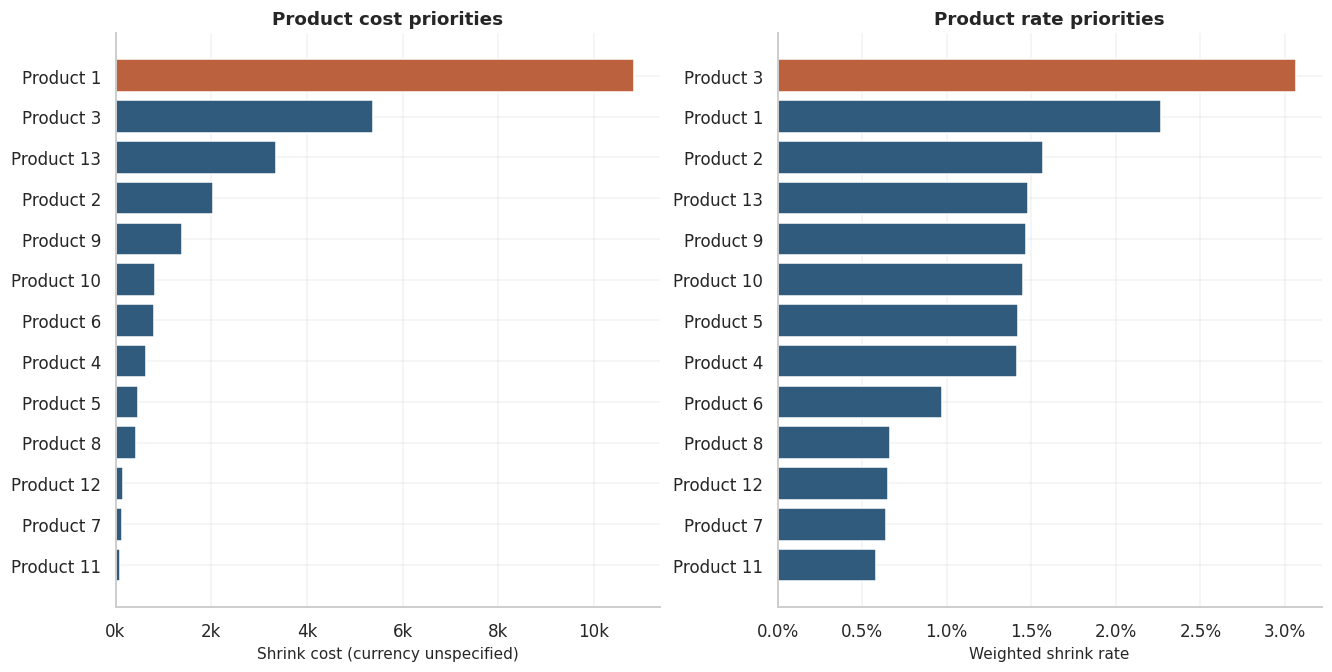

In [9]:
product_analysis = computed_summaries['products'].sort_values('total_shrink_cost',ascending=False)
product_columns = ['total_shrink_units','weighted_shrink_rate','total_shrink_cost',
                   'shrink_cost_share','rank_total_shrink_units']
display(product_analysis[product_columns].style.format({
    'total_shrink_units':'{:,}','weighted_shrink_rate':'{:.2%}',
    'total_shrink_cost':'{:,.2f}','shrink_cost_share':'{:.1%}',
}))
fig,axes = plt.subplots(1,2,figsize=(12,6),layout='constrained')
for ax,metric,title in zip(axes,['total_shrink_cost','weighted_shrink_rate'],
                          ['Product cost priorities','Product rate priorities']):
    product_order = product_analysis.sort_values(metric,ascending=False)
    colors=[ORANGE if entity==product_order.index[0] else BLUE for entity in product_order.index]
    ax.barh(['Product '+str(x) for x in product_order.index],product_order[metric],color=colors)
    ax.invert_yaxis()
    ax.set(title=title,xlabel='Weighted shrink rate' if 'rate' in metric else 'Shrink cost (currency unspecified)')
    if 'rate' in metric:
        ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=1))
    else:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_:f'{x/1000:g}k'))
plt.show()


## 8. Coded-Month Comparison
Month IDs 1–12 are compared as coded groups. Calendar names, dates, and years are not inferred. Bars avoid presenting an unverified continuous time series. Any apparent change requires a documented sequence and consistent measurement before being called a trend or seasonality.


,total_shrink_units,weighted_shrink_rate,total_shrink_cost,mean_sell_through,mean_closing_units
month_id,,,,,
1,331,1.64%,"3,263.90",34.06%,165.51
2,230,1.08%,"1,508.30",34.73%,173.94
3,292,1.57%,"2,599.40",36.57%,147.74
4,393,1.85%,"3,410.40",38.24%,163.31
5,265,1.34%,"1,837.00",38.78%,152.37
6,344,1.70%,"2,823.20",40.18%,149.62
7,262,1.26%,"2,430.10",39.29%,158.35
8,314,1.58%,"2,164.80",41.75%,144.37
9,216,1.24%,"2,116.50",42.15%,126.78


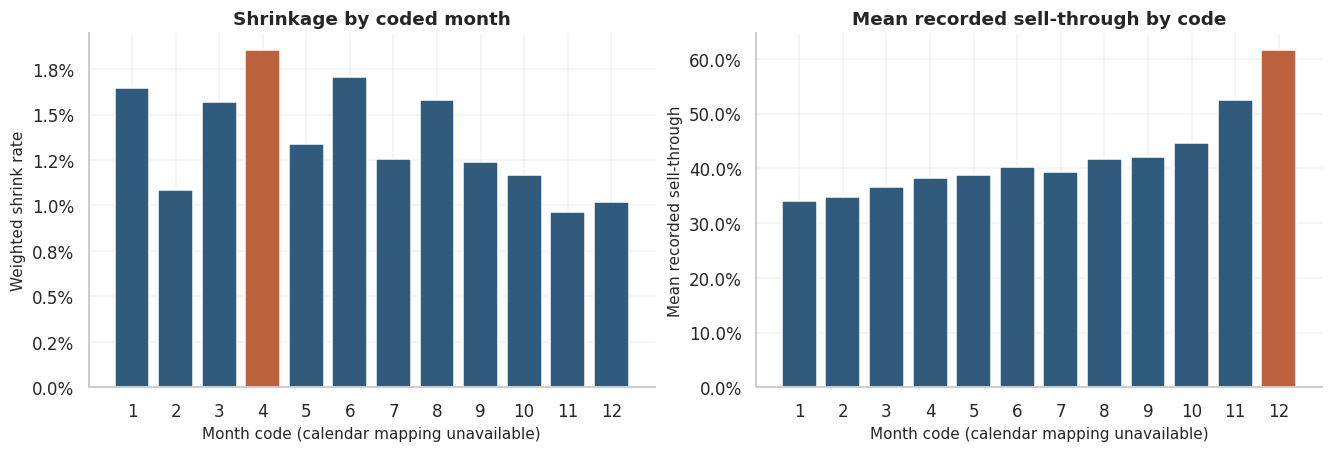

In [10]:
month_analysis = computed_summaries['months'].sort_index()
month_columns=['total_shrink_units','weighted_shrink_rate','total_shrink_cost',
               'mean_sell_through','mean_closing_units']
display(month_analysis[month_columns].style.format({
    'total_shrink_units':'{:,}','weighted_shrink_rate':'{:.2%}',
    'total_shrink_cost':'{:,.2f}','mean_sell_through':'{:.2%}','mean_closing_units':'{:,.2f}',
}))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,metric,title in zip(axes,['weighted_shrink_rate','mean_sell_through'],
                          ['Shrinkage by coded month','Mean recorded sell-through by code']):
    peak=month_analysis[metric].idxmax()
    colors=[ORANGE if entity==peak else BLUE for entity in month_analysis.index]
    ax.bar(month_analysis.index.astype(str),month_analysis[metric],color=colors)
    ax.set(title=title,xlabel='Month code (calendar mapping unavailable)',
           ylabel='Weighted shrink rate' if 'shrink' in metric else 'Mean recorded sell-through')
    ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=1))
plt.show()


## 9. Stock-Efficiency Overlap
Reproduce the supplied screening rule **within each comparison level**:

- Below the level's median of group mean recorded sell-through.
- Above the level's median of group mean closing units.
- Both conditions must hold; equality to the median is not flagged.

A flagged entity combines relatively low sell-through and relatively high stock. This does not prove overstocking without inventory age, service requirements, demand, and stockout information. Mean closing units are calculated per record, so comparisons require attention to differing product mixes and unit economics.


In [11]:
level_mapping={'store':('stores','store_id'),'product':('products','product_id'),
               'coded_month':('months','month_id')}
overlap_parts=[]
median_thresholds=[]
for level,(summary_key,id_column) in level_mapping.items():
    frame=computed_summaries[summary_key].copy()
    sell_median=frame.mean_sell_through.median()
    stock_median=frame.mean_closing_units.median()
    frame['below_median_sell_through']=frame.mean_sell_through.lt(sell_median)
    frame['above_median_closing_stock']=frame.mean_closing_units.gt(stock_median)
    frame['both_inefficiency_flags']=(frame.below_median_sell_through & frame.above_median_closing_stock)
    frame=frame.rename(columns={'rank_total_shrink_units':'shrink_volume_rank',
                                'rank_weighted_shrink_rate':'shrink_rate_rank'})
    frame.index.name='entity_id'
    frame=frame.reset_index()
    frame['level']=level
    overlap_parts.append(frame)
    median_thresholds.append({'Level':level,'Median group sell-through':sell_median,
                              'Median group closing stock':stock_median})
recomputed_overlap=pd.concat(overlap_parts,ignore_index=True)
display(pd.DataFrame(median_thresholds).set_index('Level').style.format({
    'Median group sell-through':'{:.4%}','Median group closing stock':'{:.2f}',
}))
flagged=recomputed_overlap.loc[recomputed_overlap.both_inefficiency_flags,
    ['level','entity_id','mean_sell_through','mean_closing_units',
     'total_shrink_units','weighted_shrink_rate','total_shrink_cost']]
display(flagged.sort_values(['level','entity_id']).reset_index(drop=True).style.format({
    'mean_sell_through':'{:.2%}','mean_closing_units':'{:.2f}',
    'weighted_shrink_rate':'{:.2%}','total_shrink_cost':'{:,.2f}',
}))


,Median group sell-through,Median group closing stock
Level,,
store,42.0593%,142.15
product,42.0833%,143.22
coded_month,39.7308%,148.68


,level,entity_id,mean_sell_through,mean_closing_units,total_shrink_units,weighted_shrink_rate,total_shrink_cost
0,coded_month,1,34.06%,165.51,331,1.64%,"3,263.90"
1,coded_month,2,34.73%,173.94,230,1.08%,"1,508.30"
2,coded_month,4,38.24%,163.31,393,1.85%,"3,410.40"
3,coded_month,5,38.78%,152.37,265,1.34%,"1,837.00"
4,coded_month,7,39.29%,158.35,262,1.26%,"2,430.10"
5,product,7,41.86%,152.22,122,0.64%,134.20
6,product,9,41.56%,156.82,291,1.47%,"1,396.80"
7,store,3,41.70%,143.35,501,1.27%,"3,984.00"
8,store,4,42.03%,145.09,573,1.43%,"4,453.40"


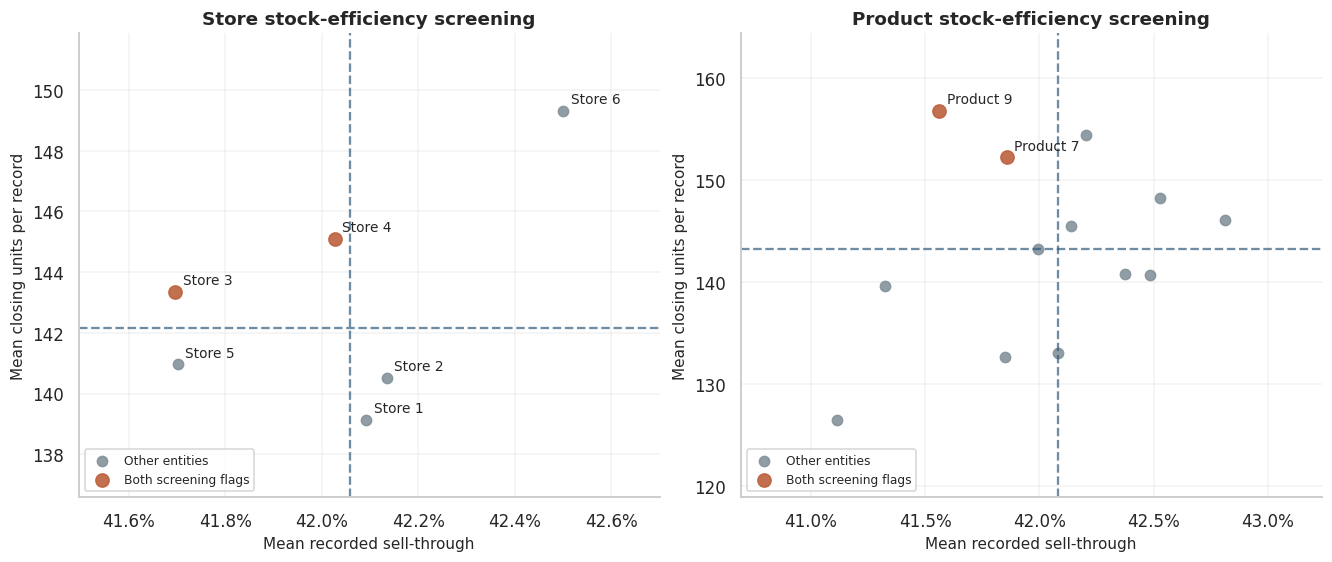

In [12]:
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax,level,label in zip(axes,['store','product'],['Store','Product']):
    frame=recomputed_overlap[recomputed_overlap.level.eq(level)]
    threshold=next(row for row in median_thresholds if row['Level']==level)
    for flag,color,legend in [(False,GRAY,'Other entities'),(True,ORANGE,'Both screening flags')]:
        subset=frame[frame.both_inefficiency_flags.eq(flag)]
        ax.scatter(subset.mean_sell_through,subset.mean_closing_units,
                   color=color,s=75 if flag else 45,label=legend,alpha=0.9)
    ax.axvline(threshold['Median group sell-through'],linestyle='--',color=BLUE,alpha=0.7)
    ax.axhline(threshold['Median group closing stock'],linestyle='--',color=BLUE,alpha=0.7)
    for row in frame.itertuples():
        if level=='store' or row.both_inefficiency_flags:
            ax.annotate(f'{label} {row.entity_id}',(row.mean_sell_through,row.mean_closing_units),
                         xytext=(5,5),textcoords='offset points',fontsize=9)
    ax.margins(x=0.25,y=0.25)
    ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=1))
    ax.set(title=label+' stock-efficiency screening',xlabel='Mean recorded sell-through',
           ylabel='Mean closing units per record')
    ax.legend(loc='lower left',fontsize=8)
plt.show()


## 10. Supporting-Summary Verification
Use the main file to independently recompute every metric represented in the four supporting files. Compare entity coverage, totals, means, weighted rates, rankings, and Boolean flags. Numeric comparisons allow only floating-point tolerance; the supplied summaries are not used as independent corroborating observations because they are aggregates of the same data.


In [13]:
def parse_boolean(series):
    parsed=series.astype(str).str.strip().str.lower().map({'true':True,'false':False})
    if parsed.isna().any():
        raise ValueError(f'Invalid Boolean values in {series.name}.')
    return parsed.astype(bool)

def verify_summary(reference,calculated,key_columns,filename):
    if reference.duplicated(key_columns).any():
        raise ValueError(f'Duplicate summary keys in {filename}.')
    expected=calculated.set_index(key_columns)
    supplied=reference.set_index(key_columns)
    if set(supplied.index)!=set(expected.index):
        raise ValueError(f'Entity coverage differs for {filename}.')
    expected=expected.loc[supplied.index]
    mismatch_count=0
    maximum_difference=0.0
    for column in supplied.columns:
        if column not in expected:
            raise ValueError(f'Cannot verify {column} in {filename}; definition unavailable.')
        if column in ['below_median_sell_through','above_median_closing_stock','both_inefficiency_flags']:
            actual_values=parse_boolean(supplied[column]).to_numpy()
            expected_values=expected[column].astype(bool).to_numpy()
            mismatch_count+=int((actual_values!=expected_values).sum())
        else:
            actual_values=pd.to_numeric(supplied[column],errors='raise').to_numpy(dtype=float)
            expected_values=expected[column].to_numpy(dtype=float)
            if not np.isfinite(actual_values).all():
                raise ValueError(f'Nonfinite summary values in {filename}: {column}.')
            mismatch_count+=int((~np.isclose(actual_values,expected_values,rtol=RTOL,atol=ATOL)).sum())
            maximum_difference=max(maximum_difference,float(np.abs(actual_values-expected_values).max()))
    return {'File':filename,'Entities':len(supplied),'Metrics checked':len(supplied.columns),
            'Mismatched cells':mismatch_count,'Max numeric difference':maximum_difference}

verification_rows=[]
for key,id_column in [('stores','store_id'),('products','product_id'),('months','month_id')]:
    verification_rows.append(verify_summary(
        source_frames[key],computed_summaries[key].reset_index(),[id_column],required_files[key]))
verification_rows.append(verify_summary(
    overlap_summary,recomputed_overlap,['level','entity_id'],required_files['overlap']))
verification_report=pd.DataFrame(verification_rows).set_index('File')
display(verification_report.style.format({'Max numeric difference':'{:.2e}'}))
if verification_report['Mismatched cells'].sum():
    raise ValueError('Supplied summaries differ from the main data. Investigate before interpreting rankings.')
print('All four supporting summaries reconcile to the main dataset.')


,Entities,Metrics checked,Mismatched cells,Max numeric difference
File,,,,
store_shrinkage_rankings.csv,6,13,0,9.02e-17
product_rankings_complete.csv,13,8,0,5.68e-14
monthly_shrinkage_summary.csv,12,9,0,9.71e-17
inefficiency_overlap_summary.csv,31,13,0,5.68e-14


All four supporting summaries reconcile to the main dataset.


No hypothesis-test results or independently evaluated predictive model are supplied. This notebook does not manufacture significance tests or classification scores from deterministic stock equations. In particular, same-record shrink cost, recorded shrink rate, and closing balances are mathematically linked to shrink units; using them to predict those units would risk giving a misleading impression of predictive skill.


## 11. Key Findings
These findings are generated from the current main-file calculations after the supporting-summary checks pass.


In [14]:
volume_store=int(store_analysis.total_shrink_units.idxmax())
rate_store=int(store_analysis.weighted_shrink_rate.idxmax())
cost_store=int(store_analysis.total_shrink_cost.idxmax())
cost_product=int(product_analysis.total_shrink_cost.idxmax())
volume_product=int(product_analysis.total_shrink_units.idxmax())
top_cost_stores=store_analysis.nlargest(2,'total_shrink_cost')
two_store_unit_share=top_cost_stores.total_shrink_units.sum()/inventory.shrink_units.sum()
peak_month=int(month_analysis.weighted_shrink_rate.idxmax())
low_month=int(month_analysis.weighted_shrink_rate.idxmin())
flag_lists={level:sorted(frame.entity_id.astype(int).tolist())
            for level,frame in flagged.groupby('level')}
display(Markdown(f'''
- **Scale:** {len(inventory):,} records cover {inventory.store_id.nunique()} stores, {inventory.product_id.nunique()} products, and {inventory.month_id.nunique()} coded months. Recorded shrink is **{inventory.shrink_units.sum():,} units**, with cost **{inventory.shrink_cost.sum():,.2f}** (currency unspecified).
- **Store priorities:** Store **{volume_store}** has the most shrink units (**{store_analysis.loc[volume_store,'total_shrink_units']:,}**). Store **{cost_store}** has the highest cost (**{store_analysis.loc[cost_store,'total_shrink_cost']:,.2f}**), and Store **{rate_store}** has the highest weighted rate (**{store_analysis.loc[rate_store,'weighted_shrink_rate']:.2%}**). The two highest-cost stores account for **{two_store_unit_share:.1%}** of shrink units.
- **Product priorities:** Product **{cost_product}** accounts for **{product_analysis.loc[cost_product,'shrink_cost_share']:.1%}** of shrink cost. Product **{volume_product}** has the highest shrink volume (**{product_analysis.loc[volume_product,'total_shrink_units']:,} units**).
- **Coded-month comparisons:** Code **{peak_month}** has the highest weighted shrink rate (**{month_analysis.loc[peak_month,'weighted_shrink_rate']:.2%}**); code **{low_month}** has the lowest (**{month_analysis.loc[low_month,'weighted_shrink_rate']:.2%}**). These are not verified calendar or seasonal patterns.
- **Efficiency overlap:** Both median-based flags identify stores **{flag_lists.get('store',[])}**, products **{flag_lists.get('product',[])}**, and coded months **{flag_lists.get('coded_month',[])}**.
- **Data integrity:** All supplied aggregate comparisons reconcile, while **{continuity_mismatches:,} of {len(continuity):,}** adjacent coded-period stock balances differ. This distinction limits inventory-ledger and forecasting interpretations.
'''))



- **Scale:** 936 records cover 6 stores, 13 products, and 12 coded months. Recorded shrink is **3,248 units**, with cost **26,560.10** (currency unspecified).
- **Store priorities:** Store **6** has the most shrink units (**804**). Store **5** has the highest cost (**6,998.60**), and Store **5** has the highest weighted rate (**1.97%**). The two highest-cost stores account for **48.5%** of shrink units.
- **Product priorities:** Product **1** accounts for **40.8%** of shrink cost. Product **3** has the highest shrink volume (**599 units**).
- **Coded-month comparisons:** Code **4** has the highest weighted shrink rate (**1.85%**); code **11** has the lowest (**0.97%**). These are not verified calendar or seasonal patterns.
- **Efficiency overlap:** Both median-based flags identify stores **[3, 4]**, products **[7, 9]**, and coded months **[1, 2, 4, 5, 7]**.
- **Data integrity:** All supplied aggregate comparisons reconcile, while **856 of 858** adjacent coded-period stock balances differ. This distinction limits inventory-ledger and forecasting interpretations.


## 12. Business Recommendations

| Priority | Recommended investigation | Outcome to measure |
| --- | --- | --- |
| Review Stores 5 and 6 | Audit receiving, counts, write-offs, and product mix; compare volume, rate, and cost together | Independently verified shrink and documented reasons |
| Prioritize Products 1 and 3 | Investigate cost exposure for Product 1 and shrink volume/rate for Product 3 | Verified unit losses and cost per affected item |
| Review dual-flag entities | Examine replenishment, stock age, demand, service levels, and stockouts for Stores 3/4 and Products 7/9 | Aged inventory, availability, sell-through, and replenishment performance |
| Establish balance continuity | Document period definitions, stock adjustments, resets, and prior-closing/current-opening differences | Unexplained balance differences after legitimate adjustments |
| Strengthen measurement | Record calendar dates, inventory counts, shrink reasons, currency, and source lineage | Reconciled stock movements and consistent financial definitions |

These actions are proposed, not implemented. The analysis does not report realized savings or identify theft, waste, process failure, or other specific causes without evidence.


## 13. Limitations and Future Work

- **Provenance and independence:** Data source, collection process, and baseline/rate-field derivations are undocumented. The four summaries derive from the main data and are not independent samples. The rounded shrink relationship warrants documentation, not an assumption that losses were physically verified.
- **Continuity:** Record-level arithmetic reconciles, but coded-period balance continuity does not. Do not interpret opening/closing discrepancies as additional shrink or use the records as a continuous stock ledger without adjustment records.
- **Calendar ambiguity:** Month codes do not establish calendar dates, a year, or a verified sequence. Forecasts and seasonal claims need a documented timeline and reconciled observations.
- **Rate denominators:** Count-based weighted shrink rate uses available-unit exposure; recorded rate fields relate differently to shrink quantities. Mean recorded rates, weighted ratios, and count-based sell-through must remain labeled distinctly.
- **Stock-efficiency screening:** Peer medians provide relative flags, not optimal stock targets or proof of inefficiency. Product units and inventory values differ; demand, lead times, inventory age, service goals, and stockout data are absent.
- **Financial scope:** Currency is unspecified. Recorded shrink cost is quantity times unit cost; operating expenses, cash effects, lost sales, and verified net-profit impacts are not supplied.
- **Statistical and predictive scope:** Rankings are descriptive. No causal effects, statistical significance, or forecasting skill are established. A future predictive study needs independently measured outcomes, purchase/count timestamps, a defined horizon, and validation using only information available before that horizon.
- **Reproducibility:** This notebook rebuilds the documented arithmetic summaries, rankings, and flags from the five CSVs and checks their agreement. It does not recreate the original source extraction/generation process, whose code was not supplied. No input files are changed and charts are embedded rather than saved as extra outputs.

**Next steps:** Confirm provenance and period mapping, reconcile balances, obtain independent counts and operational context, investigate high-priority entities, and evaluate changes with a documented baseline and controlled pilot.
